# Lab 5

    Saraliba Auch
    11/4/2026

## Proposal

**My Question:**

What is the signifcance of the drop in luminosity caused by [HIP-65 A b](https://en.wikipedia.org/wiki/HIP_65Ab) transiting its host star. What is the sigma of this event?

HIP-65 A b is a Hot Jupiter that orbits every 0.98 days. Its transit lasts for roughly 0.79 hours. Data if from the [NASA Exoplanet Archeive](https://exoplanetarchive.ipac.caltech.edu/overview/HIP%2065%20A%20b#planet_HIP-65-A-b_collapsible).


**What data I will be using:**

I will be using TESS-SPOC data to study Kepler-1946 b. TESS-SPOC is a pipeline that calibrates images from the TESS telescope, reducing the background noise so that my results will better reflect the question. The python module Lightkurve that I will be using pulls its data from [MAST](https://archive.stsci.edu/missions-and-data/kepler).


**How I will use the data to answer my question:**

There are 6 different light curves from the TESS mission. Using the lightcurves, I will develop the a distribution of the star's flux without the influence of the planetary transit. Since I know the orbital period of the planet, I will be able to fold the data. I will have to normailze the lightcurves in order to properly find the average flux. Since I will be looking at a star, I would predict it's light follows a Gaussian distribution. 

Then I would just have to find how much the planet effects the stars luminosity, and use the distribution to find the sigma of the event. 

**Data Download and Initial Plot:**

Going through lightkurve tutorial:

In [2]:
! python -m pip install lightkurve --upgrade

  Using cached lightkurve-2.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached fbpca-1.0-py3-none-any.whl
  Using cached memoization-0.4.0-py3-none-any.whl
Using cached lightkurve-2.6.0-py3-none-any.whl (261 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [lightkurve]3 [lightkurve]


In [3]:
%matplotlib inline
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
from lightkurve import search_targetpixelfile

import warnings
warnings.simplefilter('ignore')

/opt/conda/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [4]:
search = lk.search_lightcurve('HIP-65 A b', author = 'TESS-SPOC')
search

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 01,2018,TESS-SPOC,1800,201248411,0.0
1,TESS Sector 02,2018,TESS-SPOC,1800,201248411,0.0
2,TESS Sector 28,2020,TESS-SPOC,600,201248411,0.0
3,TESS Sector 29,2020,TESS-SPOC,600,201248411,0.0
4,TESS Sector 68,2023,TESS-SPOC,200,201248411,0.0
5,TESS Sector 69,2023,TESS-SPOC,200,201248411,0.0


In [5]:
lc_collection = search[:6].download_all()
lc_collection

LightCurveCollection of 6 objects:
    0: <TessLightCurve LABEL="TIC 201248411" SECTOR=1 AUTHOR=TESS-SPOC FLUX_ORIGIN=pdcsap_flux>
    1: <TessLightCurve LABEL="TIC 201248411" SECTOR=2 AUTHOR=TESS-SPOC FLUX_ORIGIN=pdcsap_flux>
    2: <TessLightCurve LABEL="TIC 201248411" SECTOR=28 AUTHOR=TESS-SPOC FLUX_ORIGIN=pdcsap_flux>
    3: <TessLightCurve LABEL="TIC 201248411" SECTOR=29 AUTHOR=TESS-SPOC FLUX_ORIGIN=pdcsap_flux>
    4: <TessLightCurve LABEL="TIC 201248411" SECTOR=68 AUTHOR=TESS-SPOC FLUX_ORIGIN=pdcsap_flux>
    5: <TessLightCurve LABEL="TIC 201248411" SECTOR=69 AUTHOR=TESS-SPOC FLUX_ORIGIN=pdcsap_flux>

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

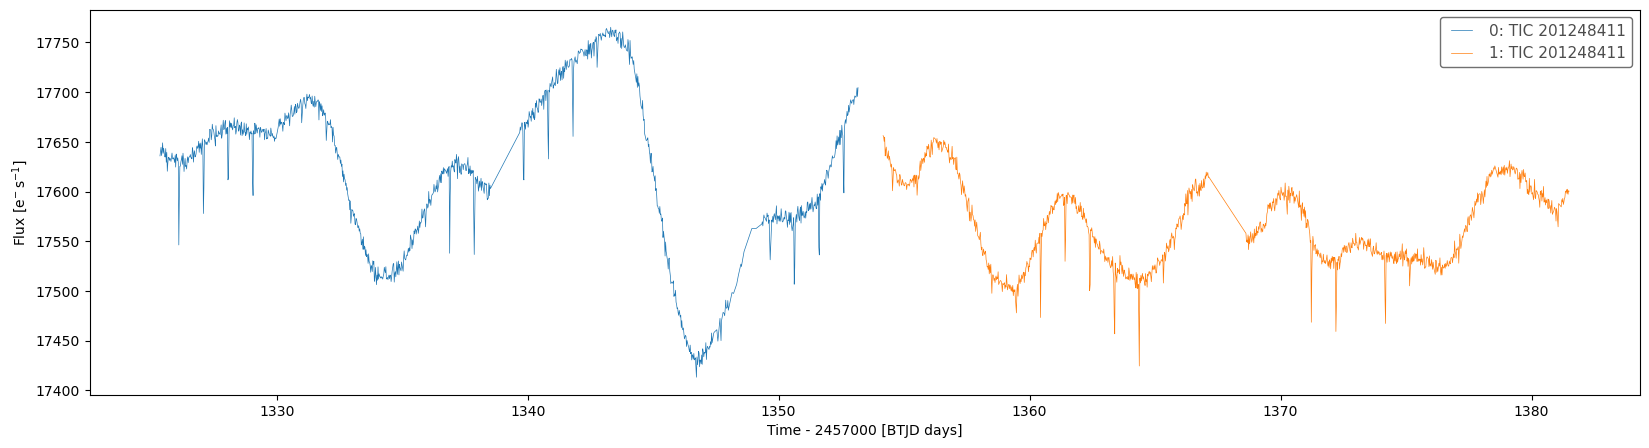

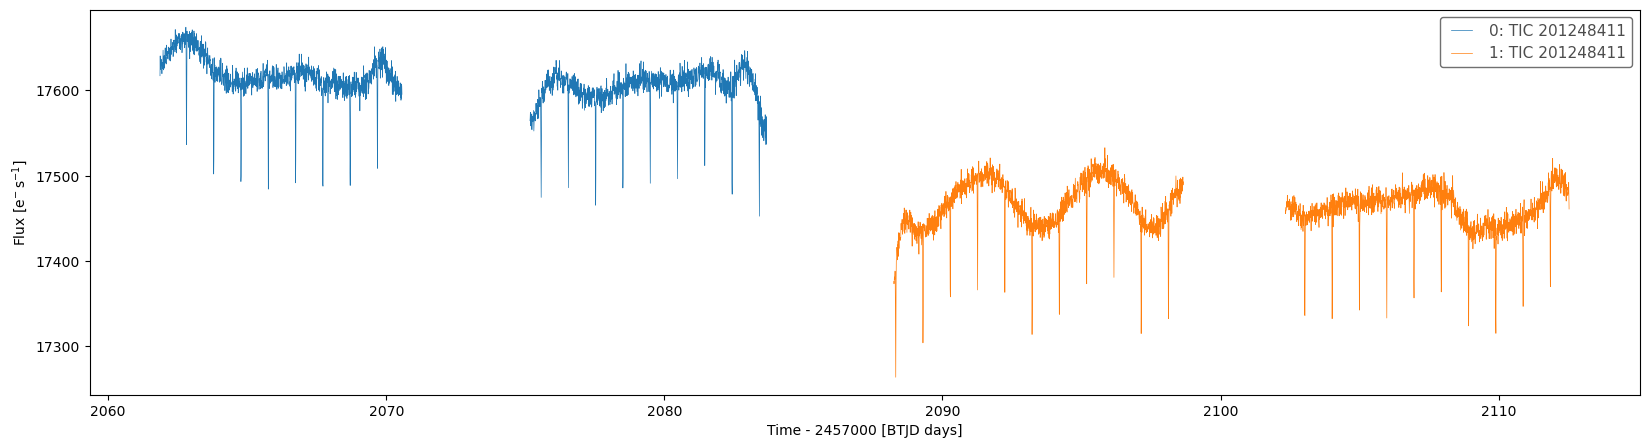

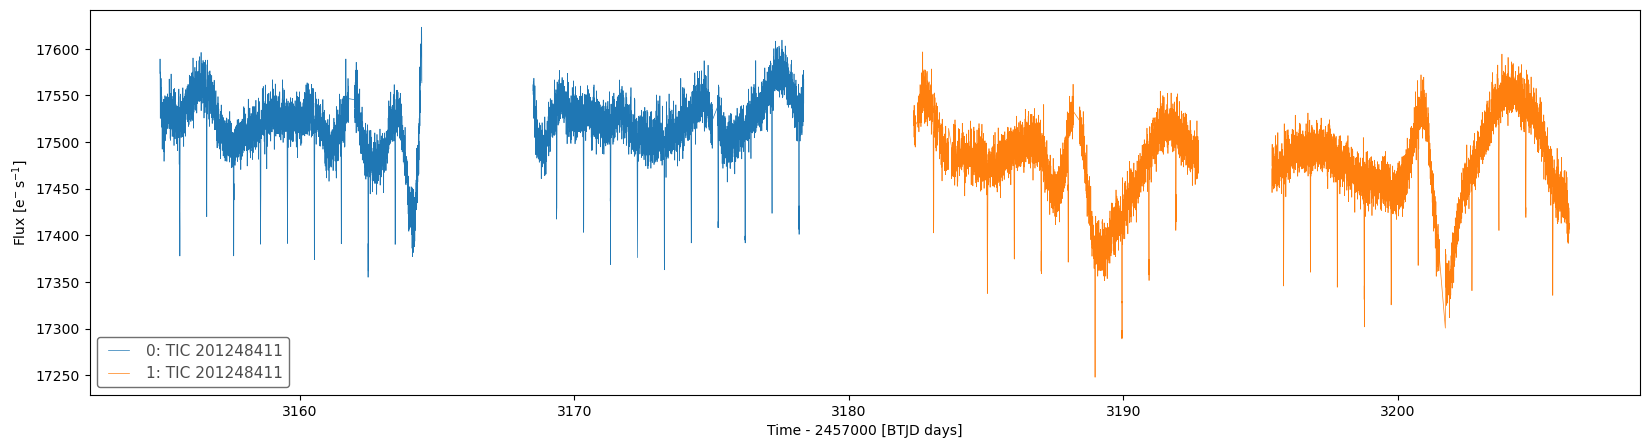

In [6]:
fig, ax = plt.subplots(figsize = (20,5))
lc_collection[:2].plot(ax=ax)
fig, ax = plt.subplots(figsize = (20,5))
lc_collection[2:4].plot(ax=ax)
fig, ax = plt.subplots(figsize = (20,5))
lc_collection[4:6].plot(ax=ax)               